# Dogs vs cats: image classification with a VGG16-style network

## Objectives

1. Understand a new image dataset: dog and cat photos from the Asirra CAPTCHA (Petfinder.com and Microsoft).
2. Model the data with an artificial neural network: the VGG16 architecture, trained from scratch.
3. Analyze the results and optimize the model with `EarlyStopping` and `ModelCheckpoint`.

**Scope:** the full set has 25,000 photos. To keep training time practical, this notebook uses a balanced, random **subset of 5,000 photos** (2,500 dogs and 2,500 cats), split 80/20 into 4,000 training and 1,000 test images. It is designed to run on a GPU: a Colab T4 runtime, connected from VS Code with the Google Colab extension.

## Setup

In [12]:
import os
import random
import shutil
import urllib.request
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from PIL import Image
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.layers import Conv2D, Dense, Flatten, Input, MaxPool2D
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import ImageDataGenerator

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Settings (small overrides via environment variables are only for quick tests)
DATA_URL = os.environ.get("DATA_URL", "https://github.com/sjcodingpro/dogs-vs-cats-classifier/archive/refs/heads/main.zip")
N_PER_CLASS = int(os.environ.get("N_PER_CLASS", 2500))  # 2,500 dogs + 2,500 cats = 5,000 photos
EPOCHS = int(os.environ.get("EPOCHS", 20))
IMG_SIZE = (200, 200)
BATCH_SIZE = 32

# Work from the repo root whether the notebook runs in src/ or in Colab
ROOT = Path.cwd().parent if Path.cwd().name == "src" else Path.cwd()
RAW_DIR = ROOT / "data" / "raw"
SUBSET_DIR = ROOT / "data" / "processed" / "subset"
MODEL_DIR = ROOT / "models"
for d in (RAW_DIR, SUBSET_DIR, MODEL_DIR):
    d.mkdir(parents=True, exist_ok=True)

print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU") or "none")

TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Step 1: Load the dataset

Download the zip, unzip it (including any zip inside it), and find the folder with the labeled `.jpg` files. Each file is labeled by its name, for example `dog.123.jpg` or `cat.45.jpg`.

In [13]:
zip_path = RAW_DIR / "dataset.zip"
if not any(RAW_DIR.rglob("*.jpg")):
    if not zip_path.exists():
        print("Downloading...")
        urllib.request.urlretrieve(DATA_URL, zip_path)
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(RAW_DIR)
    for inner in list(RAW_DIR.rglob("*.zip")):  # some versions ship train.zip inside the main zip
        if inner != zip_path:
            with zipfile.ZipFile(inner) as z:
                z.extractall(inner.parent)

all_images = [p for p in RAW_DIR.rglob("*.jpg") if p.name.split(".")[0] in ("cat", "dog")]
TRAIN_SRC = max({p.parent for p in all_images}, key=lambda d: sum(1 for p in all_images if p.parent == d))
dogs = sorted(p for p in all_images if p.parent == TRAIN_SRC and p.name.startswith("dog"))
cats = sorted(p for p in all_images if p.parent == TRAIN_SRC and p.name.startswith("cat"))
print(f"Source folder: {TRAIN_SRC}")
print(f"Found {len(dogs):,} dog photos and {len(cats):,} cat photos")

Source folder: /content/data/raw/dogs-vs-cats-classifier-main/data/raw/train
Found 2,500 dog photos and 2,500 cat photos


## Step 2: Visualize the input

The first nine dogs and the first nine cats, with each photo's original size in the title.

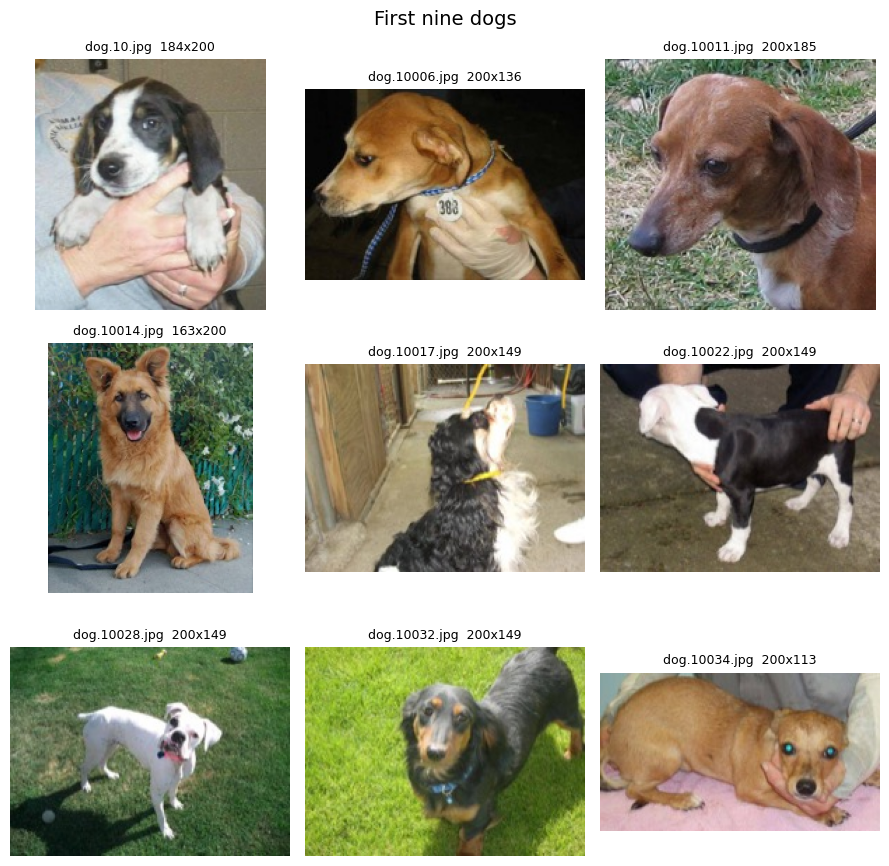

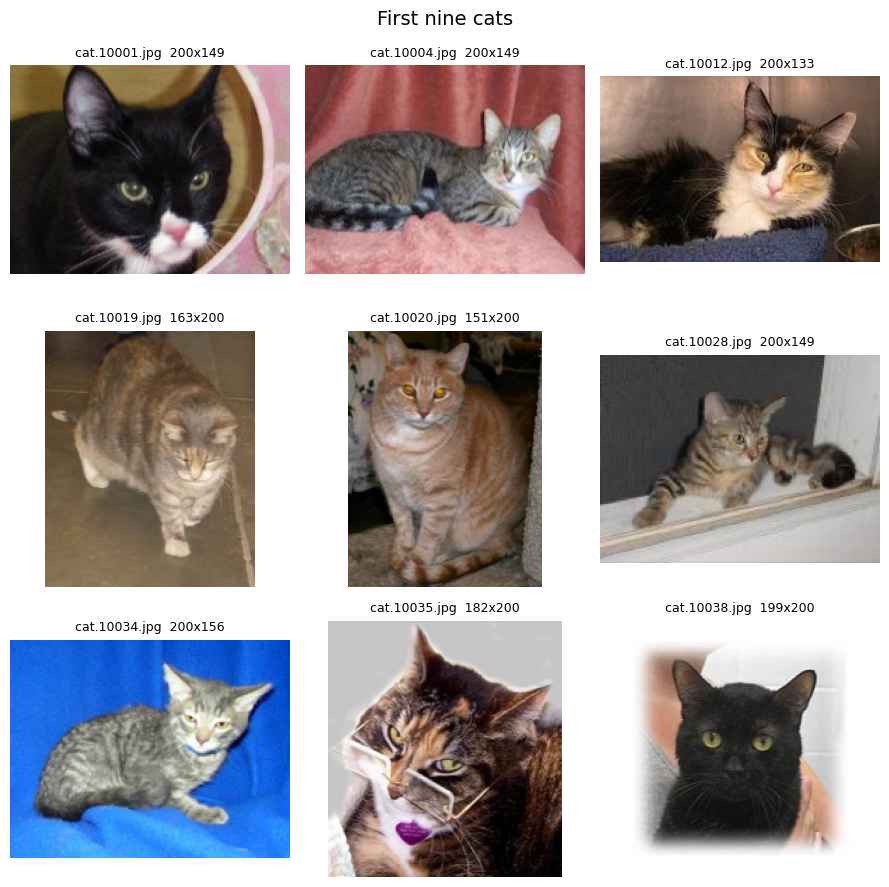

In a random sample of 200 photos, widths range 91-200 px and heights 107-200 px


In [14]:
def show_nine(paths, title):
    fig, axes = plt.subplots(3, 3, figsize=(9, 9))
    for ax, path in zip(axes.flat, paths[:9]):
        img = Image.open(path)
        ax.imshow(img)
        ax.set_title(f"{path.name}  {img.size[0]}x{img.size[1]}", fontsize=9)
        ax.axis("off")
    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()

show_nine(dogs, "First nine dogs")
show_nine(cats, "First nine cats")

sizes = [Image.open(p).size for p in random.sample(dogs + cats, min(200, len(dogs + cats)))]
widths, heights = zip(*sizes)
print(f"In a random sample of {len(sizes)} photos, widths range {min(widths)}-{max(widths)} px and heights {min(heights)}-{max(heights)} px")

The photos are in color and come in many different shapes and sizes, so they must all be resized to a fixed **200×200** before training.

### Prepare the 5,000-photo subset

With 12 GB of RAM or less (Colab and Codespaces), the photos are loaded progressively with `ImageDataGenerator.flow_from_directory()`. That function expects separate `train` and `test` folders with one subfolder per class, so a balanced random subset is copied into that layout.

In [15]:
def build_subset():
    if SUBSET_DIR.exists():
        shutil.rmtree(SUBSET_DIR)
    picked = {"dog": random.sample(dogs, N_PER_CLASS), "cat": random.sample(cats, N_PER_CLASS)}
    for label, paths in picked.items():
        split = int(len(paths) * 0.8)
        for subset, chunk in (("train", paths[:split]), ("test", paths[split:])):
            dest = SUBSET_DIR / subset / label
            dest.mkdir(parents=True, exist_ok=True)
            for p in chunk:
                shutil.copy(p, dest / p.name)

build_subset()
for subset in ("train", "test"):
    counts = {label: len(list((SUBSET_DIR / subset / label).glob("*.jpg"))) for label in ("cat", "dog")}
    print(subset, counts)

train {'cat': 2000, 'dog': 2000}
test {'cat': 500, 'dog': 500}


Now the generators. `trdata` reads the training folder and `tsdata` reads the test folder. Both rescale pixels from 0–255 to 0–1, resize every photo to 200×200 and label it from its folder name. The test generator keeps a fixed order (`shuffle=False`) so its predictions can be matched to the true labels later.

In [16]:
trdata = ImageDataGenerator(rescale=1.0 / 255)
tsdata = ImageDataGenerator(rescale=1.0 / 255)

train_data = trdata.flow_from_directory(SUBSET_DIR / "train", target_size=IMG_SIZE, batch_size=BATCH_SIZE,
                                        class_mode="categorical", shuffle=True, seed=SEED)
test_data = tsdata.flow_from_directory(SUBSET_DIR / "test", target_size=IMG_SIZE, batch_size=BATCH_SIZE,
                                       class_mode="categorical", shuffle=False)
print("Class indices:", train_data.class_indices)

Found 4000 images belonging to 2 classes.
Found 1000 images belonging to 2 classes.
Class indices: {'cat': 0, 'dog': 1}


## Step 3: Build the network

This is the VGG16 architecture given in the instructions: 13 convolution layers in 5 blocks (64, 128, 256, 512, 512 filters), each block ending in max pooling, then dense layers of 4096, 4096 and 2 units. The convolutions find edges, textures and shapes; pooling shrinks the image; the dense layers turn those features into a decision. The last layer has 2 units with softmax, so it outputs a probability for cat and for dog. The input is **200×200×3** to match our resized photos, instead of 224×224×3.

**Two additions, and why.** The first training run used the plain architecture exactly as given. It stayed stuck at **50% accuracy with a loss of 0.693** for every epoch. That loss is exactly what a model gets when it guesses 50/50, so it was learning nothing. This is a common problem when a deep network like VGG16 is trained from scratch on little data: the signal that updates the early layers fades as it passes back through 16 layers. Two standard fixes were added:
- **Batch Normalization** after every convolution. It rescales each layer's output to a stable range, so the signal keeps flowing and the network can start learning.
- **Dropout (0.5)** after the two big dense layers, as in the original VGG16 paper. It randomly switches off half the units during training, which fights overfitting.

It is compiled with:
- **Adam, learning rate 0.0001.** A small rate, which suits a deep network trained from scratch.
- **Categorical cross-entropy loss**, the standard loss for a softmax output with one-hot labels.
- **Accuracy** as the metric.

In [17]:
from tensorflow.keras.layers import Activation, BatchNormalization, Dropout

model = Sequential()
model.add(Input(shape=(*IMG_SIZE, 3)))


def vgg_block(filters, n_convs):
    """VGG16 block: n convolutions (each with batch normalization), then max pooling."""
    for _ in range(n_convs):
        model.add(Conv2D(filters=filters, kernel_size=(3, 3), padding="same"))
        model.add(BatchNormalization())
        model.add(Activation("relu"))
    model.add(MaxPool2D(pool_size=(2, 2), strides=(2, 2)))


vgg_block(64, 2)
vgg_block(128, 2)
vgg_block(256, 3)
vgg_block(512, 3)
vgg_block(512, 3)
model.add(Flatten())
model.add(Dense(units=4096, activation="relu"))
model.add(Dropout(0.5))
model.add(Dense(units=4096, activation="relu"))
model.add(Dropout(0.5))
model.add(Dense(units=2, activation="softmax"))

model.compile(optimizer=Adam(learning_rate=1e-4), loss="categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_13 (Conv2D)              │ (None, 200, 200, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 200, 200, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 200, 200, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 200, 200, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 200, 200, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 200, 200, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 100, 100, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 100, 100, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 100, 100, 128)  │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 100, 100, 128)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 100, 100, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 100, 100, 128)  │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 100, 100, 128)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 50, 50, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 50, 50, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 50, 50, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 50, 50, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 50, 50, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 50, 50, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 50, 50, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 50, 50, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 50, 50, 256)    │         1,02

 Total params: 107,022,658 (408.26 MB)

 Trainable params: 107,014,210 (408.23 MB)

 Non-trainable params: 8,448 (33.00 KB)

## Step 4: Train and optimize

Two callbacks control training:
- **ModelCheckpoint** saves the model every time validation accuracy reaches a new best, so the best version is never lost.
- **EarlyStopping** stops training when validation loss hasn't improved for 5 epochs, and restores the best weights. This avoids wasting time once the model starts overfitting. (The first version watched accuracy with a patience of 3, which was too impatient for a network that takes a few epochs to get going.)

The test folder is used as validation data here. (`fit_generator` from older Keras versions has been removed. `model.fit` now accepts generators directly and does the same job.)

In [18]:
BEST_PATH = MODEL_DIR / "vgg16_best.keras"
checkpoint = ModelCheckpoint(BEST_PATH, monitor="val_accuracy", save_best_only=True, mode="max", verbose=1)
early_stop = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True, verbose=1)
history = model.fit(train_data, validation_data=test_data, epochs=EPOCHS, callbacks=[checkpoint, early_stop])

Epoch 1/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 427ms/step - accuracy: 0.5135 - loss: 2.3046
Epoch 1: val_accuracy improved from None to 0.50000, saving model to /content/models/vgg16_best.keras

Epoch 1: finished saving model to /content/models/vgg16_best.keras
125/125 ━━━━━━━━━━━━━━━━━━━━ 113s 750ms/step - accuracy: 0.5303 - loss: 1.7827 - val_accuracy: 0.5000 - val_loss: 0.6982
Epoch 2/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 462ms/step - accuracy: 0.5597 - loss: 0.9962
Epoch 2: val_accuracy did not improve from 0.50000
125/125 ━━━━━━━━━━━━━━━━━━━━ 62s 498ms/step - accuracy: 0.5627 - loss: 1.0317 - val_accuracy: 0.5000 - val_loss: 0.9135
Epoch 3/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 498ms/step - accuracy: 0.6008 - loss: 0.8972
Epoch 3: val_accuracy did not improve from 0.50000
125/125 ━━━━━━━━━━━━━━━━━━━━ 67s 535ms/step - accuracy: 0.5893 - loss: 1.0000 - val_accuracy: 0.4990 - val_loss: 0.7697
Epoch 4/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 500ms/step - accuracy: 0.6068 - loss: 0.9938
Epoch 4: val_ac

### Training curves

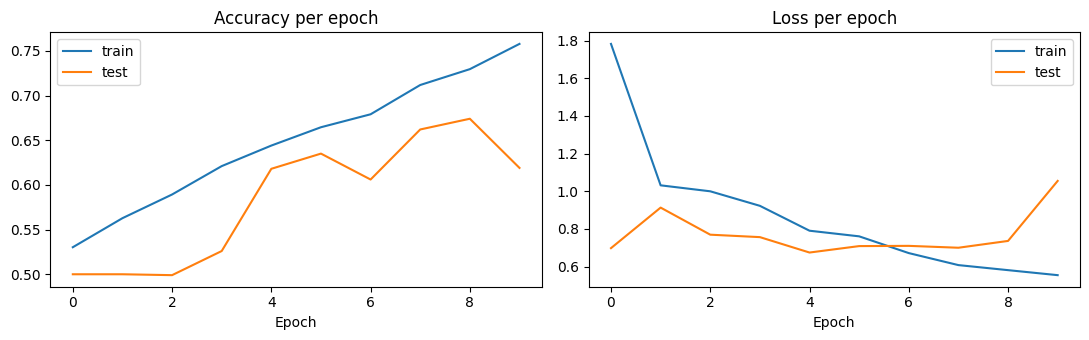

In [19]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5))
ax1.plot(history.history["accuracy"], label="train")
ax1.plot(history.history["val_accuracy"], label="test")
ax1.set_title("Accuracy per epoch")
ax1.set_xlabel("Epoch")
ax1.legend()
ax2.plot(history.history["loss"], label="train")
ax2.plot(history.history["val_loss"], label="test")
ax2.set_title("Loss per epoch")
ax2.set_xlabel("Epoch")
ax2.legend()
plt.tight_layout()
plt.show()

### Load the best model and predict on the test set

The checkpoint file holds the best epoch. It is loaded back and used to predict all 1,000 test photos.

In [20]:
best_model = load_model(BEST_PATH)
test_data.reset()
probs = best_model.predict(test_data, verbose=0)
pred = probs.argmax(axis=1)
true = test_data.classes
labels = list(test_data.class_indices.keys())

loss, acc = best_model.evaluate(test_data, verbose=0)
print(f"Best model on the test set: accuracy {acc:.3f}, loss {loss:.3f}\n")
print(classification_report(true, pred, target_names=labels))
print("Confusion matrix (rows = true, columns = predicted):")
print(confusion_matrix(true, pred))

Best model on the test set: accuracy 0.674, loss 0.736

              precision    recall  f1-score   support

         cat       0.76      0.51      0.61       500
         dog       0.63      0.84      0.72       500

    accuracy                           0.67      1000
   macro avg       0.70      0.67      0.66      1000
weighted avg       0.70      0.67      0.66      1000

Confusion matrix (rows = true, columns = predicted):
[[254 246]
 [ 80 420]]


### What does it get wrong?

326 of 1000 test photos misclassified


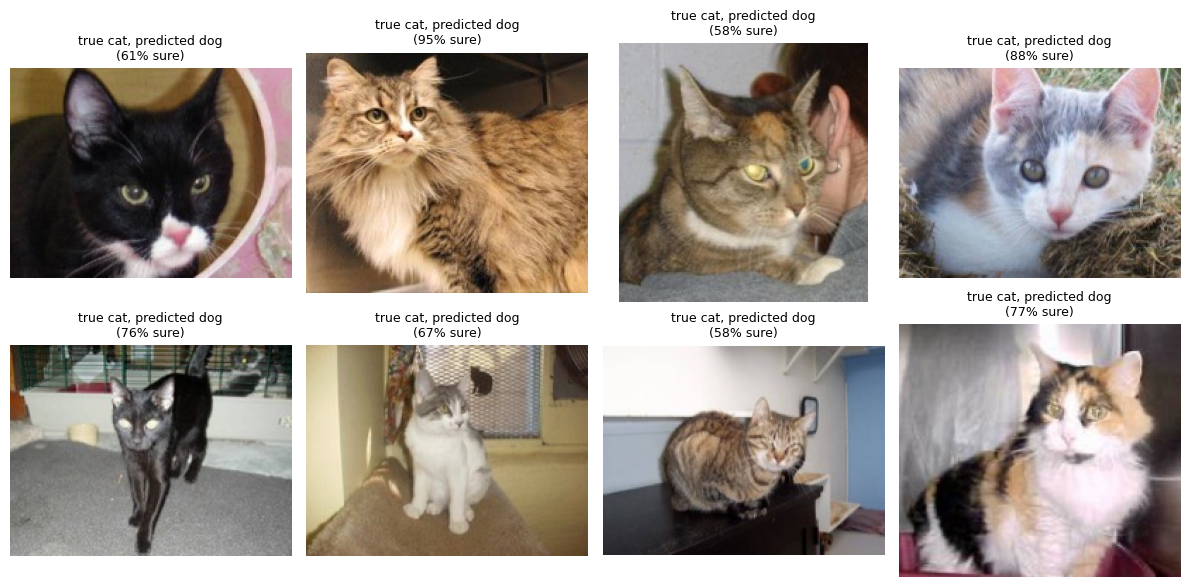

In [21]:
wrong = np.where(pred != true)[0]
print(f"{len(wrong)} of {len(true)} test photos misclassified")
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, i in zip(axes.flat, wrong[:8]):
    path = SUBSET_DIR / "test" / test_data.filenames[i]
    ax.imshow(Image.open(path))
    ax.set_title(f"true {labels[true[i]]}, predicted {labels[pred[i]]}\n({probs[i].max():.0%} sure)", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

## Step 5: Save the model

The final model is saved to the `models/` folder. The network has about 107 million weights (around 408 MB), and the saved file is about 1.3 GB because it also stores the optimizer's state. That is far over GitHub's 100 MB file limit, so it is **not committed to the repo**. Training ran on a Colab GPU runtime connected from VS Code, so the file was saved in that runtime's `models/` folder. Running this notebook recreates it.

In [22]:
FINAL_PATH = MODEL_DIR / "vgg16_cats_dogs.keras"
best_model.save(FINAL_PATH)
print(f"Saved {FINAL_PATH.relative_to(ROOT)} ({FINAL_PATH.stat().st_size / 1e6:.0f} MB)")

try:  # in Colab, also keep a copy in Google Drive
    from google.colab import drive
    drive.mount("/content/drive")
    shutil.copy(FINAL_PATH, "/content/drive/MyDrive/vgg16_cats_dogs.keras")
    print("Copied to Google Drive: MyDrive/vgg16_cats_dogs.keras")
except Exception as err:  # not in Colab, or Drive can't be mounted from this editor
    print(f"Google Drive copy skipped ({type(err).__name__}). The model stays in {MODEL_DIR}.")

Saved models/vgg16_cats_dogs.keras (1284 MB)
Google Drive copy skipped (ValueError). The model stays in /content/models.


## Conclusions

**Result.** The best model classifies **67.4% of the 1,000 test photos correctly** (test loss 0.736). That is clearly better than guessing (50%), but below the 80% the 2007 SVM paper reached, and far below what humans manage (99.6%).

**It leans towards "dog".** The confusion matrix shows the errors are not balanced:

| | Predicted cat | Predicted dog |
|---|---|---|
| **True cat** (500) | 254 | 246 |
| **True dog** (500) | 80 | 420 |

The model finds 84% of the dogs (recall 0.84) but only 51% of the cats (recall 0.51). Almost half of the cats were called dogs. When it does say "cat" it is usually right (precision 0.76), so it has learned some cat features but defaults to "dog" when unsure.

**What the training showed.**
1. **The plain architecture did not learn at all.** It stayed at 50% accuracy and a loss of 0.693, which means pure guessing. Adding Batch Normalization fixed that, and accuracy started to climb.
2. **Then it overfit.** Training accuracy kept rising (to about 76%) while test loss got worse after the middle epochs (from about 0.77 to 1.06). The model was starting to memorize the 4,000 training photos instead of learning general features. EarlyStopping caught this and stopped at epoch 10, and ModelCheckpoint kept the best version.

**Why the accuracy is limited.** VGG16 has about 107 million weights and was trained from scratch on only 4,000 photos. That is far too little data for so many weights, which is why it overfits.

**How to improve it.**
- **Transfer learning:** start from VGG16 weights already trained on ImageNet's 1.2 million photos and only retrain the last layers. That approach usually reaches well above 90% on this task.
- **Data augmentation:** random flips, rotations and zooms, so the model sees more variety from the same photos.
- **More data:** use all 25,000 photos instead of 5,000.
- **A smaller network,** which would overfit less on a small dataset.